# Aprendizaje Supervisado: Predicción de la Esperanza de Vida
## Regresión con Decision Tree, Random Forest y Support Vector Machine

**Curso:** Inteligencia Artificial 1 — Segundo Corte (Aprendizaje Supervisado)
**Dataset:** [Life Expectancy (WHO)](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who) — Kaggle

**Integrantes del grupo:**

*Arnold Steven Navarro*

*Christian Jhose Moreno Rios*

*Julian Andres Rodriguez Montero*

*Marcelo Gomez Cabra*

---

1. Planteamiento del problema · 2. ¿Por qué regresión? · 3. Preparación · 4. Partición 80/20 aleatoria · 5. Los tres modelos y métricas · 6. Entrenamiento base · 7. Hiperparámetros (búsqueda + estudio) · 8. Comparación (tabla general, dónde falla, matriz por rangos, correlaciones) · 9. Mejor modelo y análisis de errores · 10. Conclusiones


## 1. Planteamiento del problema

En el primer corte hicimos el EDA de este dataset y vimos que la esperanza de vida (`Life expectancy`) está muy asociada a variables como `Schooling`, `Income composition of resources`, `Adult Mortality` y `HIV/AIDS`.

En este corte pasamos de **describir** los datos a **predecir**: entrenar modelos de aprendizaje supervisado que, dadas las características de un país en un año (salud, inmunización, economía, educación), estimen su esperanza de vida.

**Variable objetivo (target):** `Life expectancy` — esperanza de vida al nacer, en años.

**Configuración del experimento:**
- Partición **80 % entrenamiento / 20 % prueba** (`test_size = 0.20`).
- Tres modelos de regresión recomendados por el profesor: **Decision Tree**, **Random Forest** y **Support Vector Machine (SVR)**.
- Métricas de comparación: **R²**, **MAE** y **RMSE** sobre el conjunto de prueba.


## 2. ¿Por qué regresión y no clasificación?

La elección entre regresión y clasificación depende de **la naturaleza de la variable objetivo**:

| | Clasificación | Regresión |
|---|---|---|
| Qué predice | Una **categoría** (clase) | Un **valor numérico continuo** |
| Ejemplo | ¿Es un país "Developed" o "Developing"? | ¿Cuántos años vive en promedio la población de un país? |

Nuestro target, `Life expectancy`, es **numérico continuo** (años con decimales, p. ej. 65.0, 59.9, 77.8) y toma cientos de valores distintos, por eso el problema es de **regresión**.

**Por qué no convertirlo en clasificación:** podríamos agrupar la esperanza de vida en rangos (p. ej. "baja", "media", "alta"), pero eso tiene desventajas:
1. **Se pierde información**: un país con 59 años y otro con 60 quedarían en grupos distintos si el corte está en 60, mientras que 60 y 74 quedarían juntos.
2. **Los umbrales son arbitrarios** y cambiarlos cambia el resultado.
3. **La respuesta es menos útil**: para política pública interesa saber *cuántos años* de diferencia hay, no solo la categoría.

(`Status` sí es una variable categórica, pero es una **característica de entrada** de nuestro modelo, no lo que queremos predecir.)


## 3. Carga de datos

Subimos el mismo `Life Expectancy Data.csv` de Kaggle que usamos en el EDA.

In [ ]:
# --- Opción A: subir el archivo manualmente (Colab) ---
try:
    from google.colab import files
    print("Sube el archivo 'Life Expectancy Data.csv' descargado de Kaggle:")
    uploaded = files.upload()
    RUTA_CSV = list(uploaded.keys())[0]
except ImportError:
    # Entorno local (no Colab): ajusta la ruta manualmente
    RUTA_CSV = "data/Life Expectancy Data.csv"


Sube el archivo 'Life Expectancy Data.csv' descargado de Kaggle:


Saving Life Expectancy Data.csv to Life Expectancy Data.csv


In [ ]:
# --- Opción B (alternativa): montar Google Drive ---
# from google.colab import drive
# drive.mount('/content/drive')
# RUTA_CSV = "/content/drive/MyDrive/ruta/a/Life Expectancy Data.csv"


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42   # semilla fija para que los resultados sean reproducibles
TEST_SIZE = 0.20    # 20 % para prueba, como pide el enunciado

df = pd.read_csv(RUTA_CSV)

# El CSV original trae espacios extra (inicio, final y dobles) en varios nombres de columna
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)

TARGET = "Life expectancy"
print("Dimensiones originales:", df.shape)
df.head()


Dimensiones originales: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 4. Preparación de los datos

Decisiones tomadas (todas justificadas por lo visto en el EDA):

1. **Filas sin target:** si `Life expectancy` es nula no hay nada que aprender ni evaluar, así que esas filas se eliminan.
2. **`Country` se excluye de las características:** tiene ~193 valores distintos; codificarlo añadiría casi 200 columnas y permitiría al modelo "memorizar países" en lugar de aprender de los factores de salud y economía.
3. **`Status` se convierte a 0/1** (`Status_Developed` = 1 si el país es Developed), porque los modelos necesitan entradas numéricas.
4. **`Year` se conserva** como característica numérica (captura la tendencia temporal 2000-2015).
5. **Valores nulos:** NO se imputan ahora sino **dentro de un Pipeline** (con la mediana, igual que en el EDA). Así la mediana se calcula **solo con los datos de entrenamiento** y se evita *data leakage* (que información del conjunto de prueba influya en el entrenamiento).


In [ ]:
# 1. Eliminar filas sin target
n_antes = len(df)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Filas eliminadas por target nulo: {n_antes - len(df)}  ->  quedan {len(df)}")

# 3. Status -> 0/1
df["Status_Developed"] = (df["Status"] == "Developed").astype(int)

# 2. y 3. Definir características (X) y objetivo (y)
FEATURES = [c for c in df.columns if c not in [TARGET, "Country", "Status"]]
X = df[FEATURES]
y = df[TARGET]

print(f"\nNúmero de características: {len(FEATURES)}")
print(FEATURES)
print("\nValores nulos por característica (se imputarán dentro del Pipeline):")
nulos = X.isna().sum()
print(nulos[nulos > 0].sort_values(ascending=False))


Filas eliminadas por target nulo: 10  ->  quedan 2928

Número de características: 20
['Year', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Status_Developed']

Valores nulos por característica (se imputarán dentro del Pipeline):
Population                         644
Hepatitis B                        553
GDP                                443
Total expenditure                  226
Alcohol                            193
Schooling                          160
Income composition of resources    160
BMI                                 32
thinness 1-19 years                 32
thinness 5-9 years                  32
Polio                               19
Diphtheria                          19
dtype: int64


## 5. Partición entrenamiento / prueba (80 % / 20 %)

La partición se hace **antes** de cualquier ajuste del modelo. El conjunto de prueba queda "bloqueado" hasta la evaluación final: simula datos nuevos que el modelo nunca ha visto.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"Entrenamiento: {X_train.shape[0]} filas ({X_train.shape[0]/len(X):.0%})")
print(f"Prueba:        {X_test.shape[0]} filas ({X_test.shape[0]/len(X):.0%})")
print(f"\nLife expectancy — media train: {y_train.mean():.2f} | media test: {y_test.mean():.2f}")


Entrenamiento: 2342 filas (80%)
Prueba:        586 filas (20%)

Life expectancy — media train: 69.15 | media test: 69.53


> **Nota metodológica:** el dataset tiene varias filas por país (una por año). Con una partición aleatoria, años cercanos del mismo país pueden quedar uno en train y otro en test, lo que hace el problema algo más fácil que predecir un país completamente nuevo. Seguimos la partición aleatoria 80/20 pedida en el enunciado, y dejamos esta limitación anotada en las conclusiones.

## 6. Los tres modelos de regresión

| Modelo | Idea en una frase | Necesita escalar los datos |
|---|---|---|
| **Decision Tree** | Hace preguntas del tipo "¿Schooling > 12?" y predice el promedio de cada hoja | No |
| **Random Forest** | Promedia muchos árboles entrenados con subconjuntos aleatorios de datos y variables | No |
| **SVR** (Support Vector Regression) | Busca una función que se ajuste a los datos tolerando un margen de error ε; usa distancias | **Sí** |

Por eso el `Pipeline` del SVR incluye `StandardScaler` (escalar las variables) y además se escala el target con `TransformedTargetRegressor`: el parámetro ε del SVR está en las unidades del target, y estandarizarlo hace que los valores por defecto sean razonables.


In [ ]:
def modelo_arbol(**kw):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=RANDOM_STATE, **kw)),
    ])

def modelo_bosque(**kw):
    kw.setdefault("n_jobs", -1)
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(random_state=RANDOM_STATE, **kw)),
    ])

def modelo_svr(**kw):
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(**kw)),
    ])
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluar(nombre, modelo):
    """Métricas en train, en test y validación cruzada (5 folds) sobre train."""
    pred_tr = modelo.predict(X_train)
    pred_te = modelo.predict(X_test)
    cv = cross_val_score(modelo, X_train, y_train, cv=kf, scoring="r2")
    return {
        "Modelo": nombre,
        "R² train": r2_score(y_train, pred_tr),
        "R² CV (media)": cv.mean(),
        "R² test": r2_score(y_test, pred_te),
        "MAE test (años)": mean_absolute_error(y_test, pred_te),
        "RMSE test (años)": np.sqrt(mean_squared_error(y_test, pred_te)),
    }


### 6.1 Métricas de evaluación

- **R²** (coeficiente de determinación): fracción de la variabilidad de la esperanza de vida que explica el modelo. 1 = perfecto, 0 = no mejora a predecir siempre el promedio.
- **MAE** (error absoluto medio): error promedio en **años**. Fácil de interpretar.
- **RMSE** (raíz del error cuadrático medio): también en años, pero penaliza más los errores grandes.
- **R² train vs R² test:** si el de train es mucho mayor, hay **sobreajuste** (el modelo memoriza en vez de generalizar).


## 7. Entrenamiento base (hiperparámetros por defecto)

Primero entrenamos los tres modelos "tal cual" para tener un punto de referencia.

In [ ]:
baseline = {
    "Decision Tree": modelo_arbol(),
    "Random Forest": modelo_bosque(n_estimators=100),
    "SVR": modelo_svr(),
}

resultados_base = []
for nombre, modelo in baseline.items():
    modelo.fit(X_train, y_train)
    resultados_base.append(evaluar(nombre, modelo))

tabla_base = pd.DataFrame(resultados_base).set_index("Modelo").round(3)
tabla_base


,R² train,R² CV (media),R² test,MAE test (años),RMSE test (años)
Modelo,,,,,
Decision Tree,1.000,0.904,0.923,1.498,2.587
Random Forest,0.995,0.957,0.968,1.053,1.675
SVR,0.953,0.922,0.923,1.689,2.578


## 8. Ajuste de hiperparámetros (GridSearchCV)

Cada modelo tiene "perillas" (hiperparámetros) que controlan su complejidad. Probamos una grilla pequeña por modelo con **validación cruzada de 5 folds sobre el conjunto de entrenamiento** (el de prueba sigue sin tocarse) y nos quedamos con la mejor combinación según R².

| Modelo | Hiperparámetros probados | Qué controlan |
|---|---|---|
| Decision Tree | `max_depth`, `min_samples_leaf` | Profundidad del árbol y tamaño mínimo de hoja (frenan el sobreajuste) |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf` | Número de árboles y su complejidad |
| SVR | `C`, `epsilon`, `gamma` | Penalización por error, margen de tolerancia y alcance de cada punto |


In [ ]:
grillas = {
    "Decision Tree": (
        modelo_arbol(),
        {"model__max_depth": [4, 6, 8, 12, None],
         "model__min_samples_leaf": [1, 3, 5, 10]},
    ),
    "Random Forest": (
        modelo_bosque(n_estimators=100, n_jobs=1),
        {"model__n_estimators": [100, 300],
         "model__max_depth": [None, 20],
         "model__min_samples_leaf": [1, 2]},
    ),
    "SVR": (
        modelo_svr(),
        {"regressor__model__C": [1, 10, 100],
         "regressor__model__epsilon": [0.05, 0.1, 0.2],
         "regressor__model__gamma": ["scale", 0.01]},
    ),
}

ajustados = {}
for nombre, (modelo, grilla) in grillas.items():
    gs = GridSearchCV(modelo, grilla, cv=kf, scoring="r2", n_jobs=-1)
    gs.fit(X_train, y_train)
    ajustados[nombre] = gs
    print(f"{nombre:14s} | mejor R² CV = {gs.best_score_:.3f} | {gs.best_params_}")


Decision Tree  | mejor R² CV = 0.921 | {'model__max_depth': 8, 'model__min_samples_leaf': 5}
Random Forest  | mejor R² CV = 0.957 | {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
SVR            | mejor R² CV = 0.935 | {'regressor__model__C': 10, 'regressor__model__epsilon': 0.05, 'regressor__model__gamma': 'scale'}


In [ ]:
resultados_aj = [evaluar(nombre, gs.best_estimator_) for nombre, gs in ajustados.items()]
tabla_aj = pd.DataFrame(resultados_aj).set_index("Modelo").round(3)
tabla_aj


,R² train,R² CV (media),R² test,MAE test (años),RMSE test (años)
Modelo,,,,,
Decision Tree,0.964,0.921,0.933,1.652,2.406
Random Forest,0.995,0.957,0.967,1.056,1.686
SVR,0.976,0.935,0.932,1.481,2.421


> Nota: el R² CV de los modelos ajustados es ligeramente optimista, porque los hiperparámetros se eligieron justamente sobre esos mismos folds. La métrica **R² test** es la comparación honesta, porque esos datos nunca se usaron para entrenar ni para elegir parámetros.

## 9. Comparación de modelos

In [ ]:
comparacion = pd.concat(
    [tabla_base.assign(Versión="Base"), tabla_aj.assign(Versión="Ajustado")]
).reset_index().sort_values("R² test", ascending=False).reset_index(drop=True)
comparacion[["Modelo", "Versión", "R² train", "R² CV (media)", "R² test",
             "MAE test (años)", "RMSE test (años)"]]


,Modelo,Versión,R² train,R² CV (media),R² test,MAE test (años),RMSE test (años)
0,Random Forest,Base,0.995,0.957,0.968,1.053,1.675
1,Random Forest,Ajustado,0.995,0.957,0.967,1.056,1.686
2,Decision Tree,Ajustado,0.964,0.921,0.933,1.652,2.406
3,SVR,Ajustado,0.976,0.935,0.932,1.481,2.421
4,Decision Tree,Base,1.000,0.904,0.923,1.498,2.587
5,SVR,Base,0.953,0.922,0.923,1.689,2.578


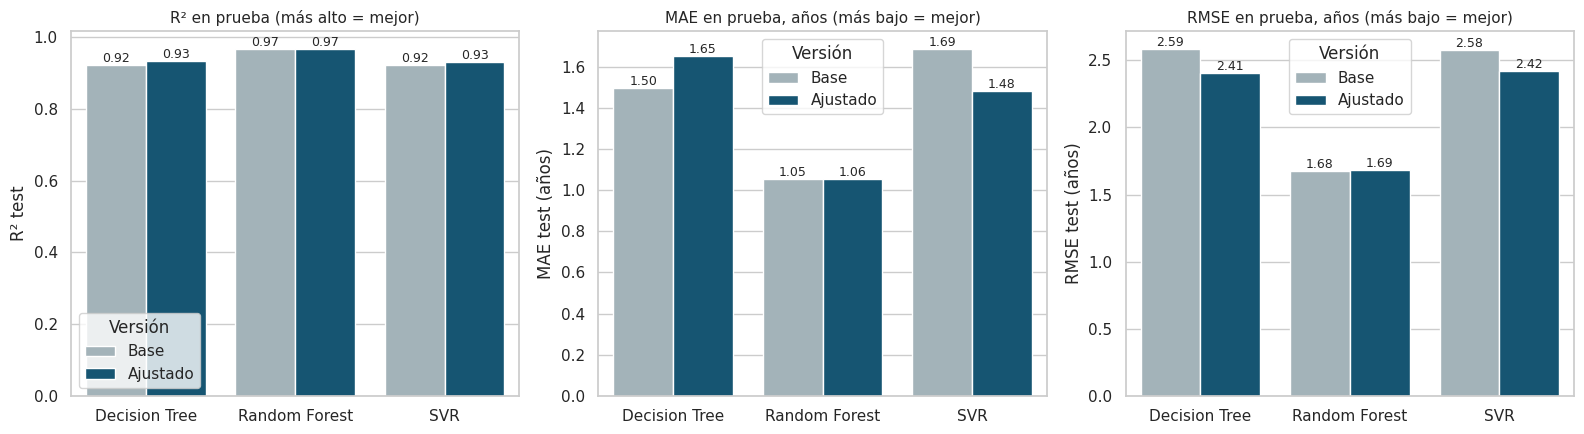

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
orden = ["Decision Tree", "Random Forest", "SVR"]
colores = {"Base": "#9FB4BD", "Ajustado": "#065A82"}

for ax, metrica, titulo in zip(
    axes,
    ["R² test", "MAE test (años)", "RMSE test (años)"],
    ["R² en prueba (más alto = mejor)", "MAE en prueba, años (más bajo = mejor)", "RMSE en prueba, años (más bajo = mejor)"],
):
    sns.barplot(data=comparacion, x="Modelo", y=metrica, hue="Versión", order=orden,
                palette=colores, ax=ax)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=9)
plt.tight_layout()
plt.show()


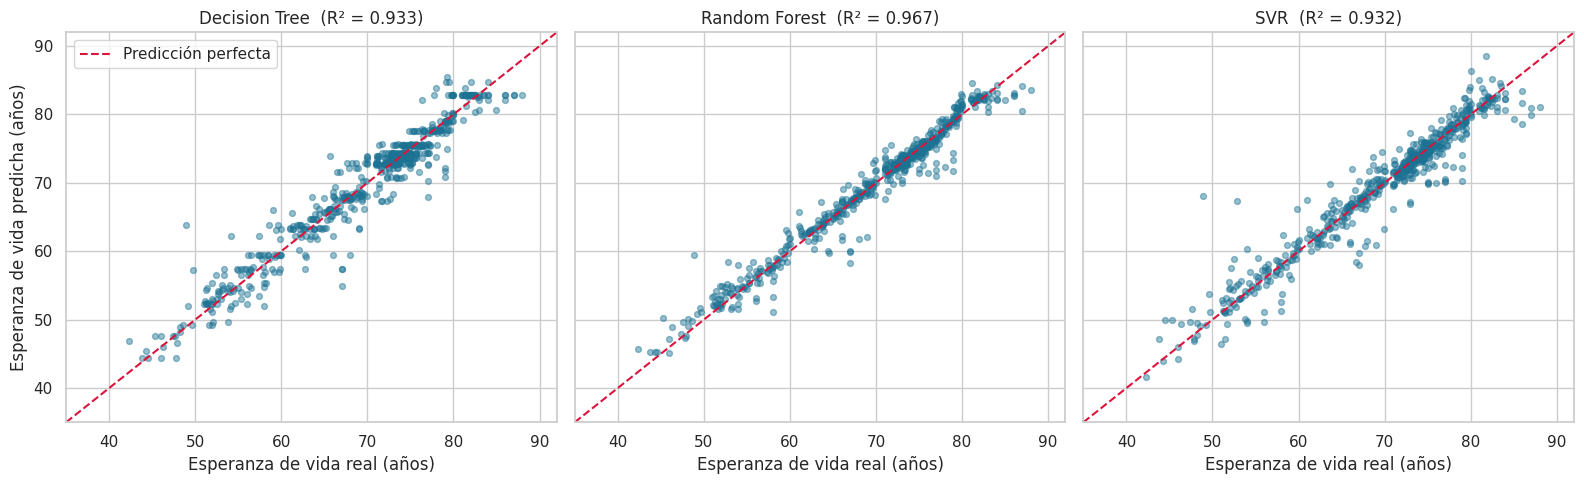

In [ ]:
# Predicho vs real (modelos ajustados) — los puntos cerca de la diagonal son buenas predicciones
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lim = [min(y_test.min(), 35), max(y_test.max(), 92)]

for ax, (nombre, gs) in zip(axes, ajustados.items()):
    pred = gs.best_estimator_.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.45, s=18, color="#1C7293")
    ax.plot(lim, lim, color="crimson", linestyle="--", label="Predicción perfecta")
    r2 = r2_score(y_test, pred)
    ax.set_title(f"{nombre}  (R² = {r2:.3f})")
    ax.set_xlabel("Esperanza de vida real (años)")
    ax.set_xlim(lim); ax.set_ylim(lim)
axes[0].set_ylabel("Esperanza de vida predicha (años)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()


## 10. Mejor modelo

In [ ]:
mejor_test = comparacion.iloc[0]
mejor_cv = comparacion.sort_values("R² CV (media)", ascending=False).iloc[0]

print(f"Mejor según R² en prueba : {mejor_test['Modelo']} ({mejor_test['Versión']})")
print(f"Mejor según R² en CV     : {mejor_cv['Modelo']} ({mejor_cv['Versión']})")
print()
print(f"-> {mejor_test['Modelo']} ({mejor_test['Versión']}): "
      f"R² = {mejor_test['R² test']:.3f}, "
      f"MAE = {mejor_test['MAE test (años)']:.2f} años, "
      f"RMSE = {mejor_test['RMSE test (años)']:.2f} años")

NOMBRE_MEJOR = mejor_test["Modelo"]
MODELO_MEJOR = (ajustados[NOMBRE_MEJOR].best_estimator_ if mejor_test["Versión"] == "Ajustado"
                else baseline[NOMBRE_MEJOR])


Mejor según R² en prueba : Random Forest (Base)
Mejor según R² en CV     : Random Forest (Base)

-> Random Forest (Base): R² = 0.968, MAE = 1.05 años, RMSE = 1.68 años


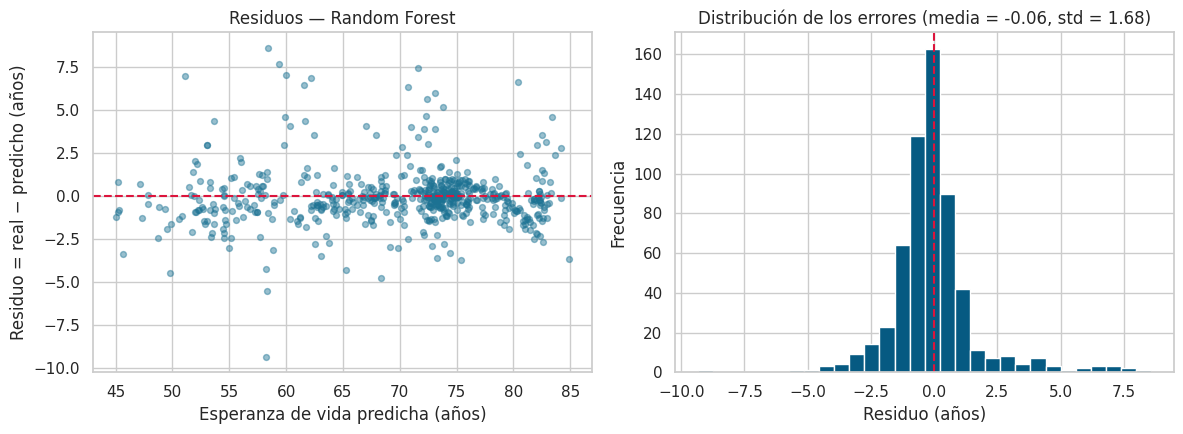

In [ ]:
# Residuos del mejor modelo: error = real - predicho
pred_mejor = MODELO_MEJOR.predict(X_test)
residuos = y_test - pred_mejor

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(pred_mejor, residuos, alpha=0.45, s=18, color="#1C7293")
axes[0].axhline(0, color="crimson", linestyle="--")
axes[0].set_xlabel("Esperanza de vida predicha (años)")
axes[0].set_ylabel("Residuo = real − predicho (años)")
axes[0].set_title(f"Residuos — {NOMBRE_MEJOR}")

axes[1].hist(residuos, bins=30, color="#065A82", edgecolor="white")
axes[1].axvline(0, color="crimson", linestyle="--")
axes[1].set_xlabel("Residuo (años)")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title(f"Distribución de los errores (media = {residuos.mean():.2f}, std = {residuos.std():.2f})")
plt.tight_layout()
plt.show()


### 10.1 ¿Qué variables usa el Random Forest?

Los árboles permiten ver qué variables aportaron más a las predicciones (*importancia de características*). Es una forma de conectar el modelo con los patrones encontrados en el EDA.

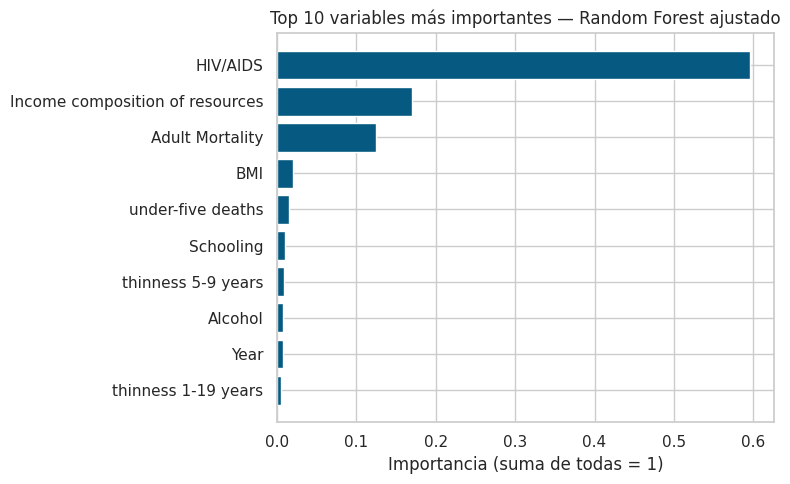

,0
HIV/AIDS,0.596
Income composition of resources,0.170
Adult Mortality,0.125
BMI,0.020
under-five deaths,0.016
Schooling,0.011
thinness 5-9 years,0.009
Alcohol,0.008
Year,0.007
thinness 1-19 years,0.005


In [ ]:
rf = ajustados["Random Forest"].best_estimator_.named_steps["model"]
importancias = (pd.Series(rf.feature_importances_, index=X.columns)
                .sort_values(ascending=False))

top = importancias.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="#065A82")
plt.xlabel("Importancia (suma de todas = 1)")
plt.title("Top 10 variables más importantes — Random Forest ajustado")
plt.tight_layout()
plt.show()

importancias.head(10).round(3)


In [ ]:
# Ejemplo de uso: el mejor modelo prediciendo 8 filas del conjunto de prueba
ejemplo = X_test.head(8).copy()
ejemplo["Real"] = y_test.head(8).values
ejemplo["Predicho"] = MODELO_MEJOR.predict(X_test.head(8)).round(1)
ejemplo["Error (años)"] = (ejemplo["Real"] - ejemplo["Predicho"]).round(1)
ejemplo[["Year", "Schooling", "Adult Mortality", "Real", "Predicho", "Error (años)"]]


,Year,Schooling,Adult Mortality,Real,Predicho,Error (años)
2390,2009,12.8,449.0,56.5,55.4,1.1
196,2011,9.4,14.0,73.0,70.2,2.8
2307,2012,15.4,59.0,82.5,82.2,0.3
1731,2012,15.1,11.0,75.6,76.0,-0.4
1100,2003,7.4,38.0,53.0,53.8,-0.8
1192,2007,9.9,26.0,65.2,65.0,0.2
1505,2014,13.4,143.0,72.4,73.7,-1.3
1159,2008,15.3,165.0,74.1,73.9,0.2


## 11. Conclusiones y próximos pasos

**Resultados principales (conjunto de prueba, 586 registros):**

- **Mejor modelo: Random Forest base**, con R² = 0.968, MAE = 1.05 años y RMSE = 1.68 años. Su versión ajustada (300 árboles, profundidad 20) rinde igual (R² 0.967): la diferencia es ruido, porque ambos dan 0.957 en validación cruzada.
- **Sobreajuste:** el Decision Tree base memoriza (R² train 1.000 frente a 0.923 en prueba). Limitar `max_depth = 8` y `min_samples_leaf = 5` sube la prueba a 0.933. El Random Forest tiene R² train 0.995, pero generaliza bien (0.957 en CV y 0.968 en prueba) porque promediar árboles reduce la varianza.
- **SVR:** es el que más depende de los hiperparámetros; con `C = 10`, `epsilon = 0.05` y `gamma = "scale"` baja su MAE de 1.69 a 1.48 años.
- **Variables importantes:** el bosque se apoya en `HIV/AIDS` (0.596), `Income composition of resources` (0.170) y `Adult Mortality` (0.125), que suman el 89 %. Coinciden con las variables más correlacionadas del EDA.
- **Dónde falla:** el error crece en países con baja esperanza de vida (MAE 1.39 años bajo 60, frente a 0.90 sobre 70). Los errores mayores corresponden a crisis ligadas al VIH (Sudán del Sur 2000, Zimbabue 2015, Uganda 2013).
- La comparación con una **red neuronal densa (MLP)** y la validación por país (`GroupKFold`) están en `unsupervised_learning.ipynb`, sección 2.

**Limitaciones:**
- Hay varias filas por país: la partición aleatoria deja años vecinos del mismo país en train y test, lo que puede **inflar** el R² frente a predecir un país nuevo.
- Se imputaron nulos con la mediana (simple); una imputación por país o por `Status` podría ser mejor.
- Algunas variables tienen outliers y valores extraños heredados del dataset original (p. ej. población o GDP con magnitudes inconsistentes en ciertos años).

**Próximos pasos:**
1. Validar por país (`GroupKFold`): ya se midió en `unsupervised_learning.ipynb` (R² 0.903 y MAE 2.11 años para países no vistos).
2. Probar transformación logarítmica de `GDP`, `Population` y `Measles`.
3. Explorar otros modelos (Gradient Boosting) y selección de características.
